# RF Intrusion CNN v1/v2 — Local Training and Evaluation

This notebook trains and evaluates the baseline CNN v1 and improved CNN v2 **locally in a TensorFlow Docker GPU container**. It reads the existing curated assignment split from `data/kaggle_assignment_split/rf_assignment_split` and writes native Keras artifacts, metrics JSON, and confusion-matrix images to `artifacts/tensorflow_training`. It does not use SageMaker or modify S3.

## Run local GPU training with Docker Desktop

1. Install Docker Desktop for Windows with the **WSL 2 based engine** enabled. GPU passthrough requires a supported NVIDIA GPU, a current NVIDIA Windows driver with WSL 2 support, and Docker Desktop running Linux containers.
2. In PowerShell, change to this project root and confirm that Docker can see the GPU:

```powershell
docker run --rm --gpus all ubuntu nvidia-smi
```

3. Start the TensorFlow GPU Jupyter image. `${PWD}` is mounted as `/workspace`, so the dataset and generated artifacts persist on the Windows host after the container stops:

```powershell
docker run --rm --gpus all -p 8888:8888 -v "${PWD}:/workspace" -w /workspace tensorflow/tensorflow:latest-gpu-jupyter
```

4. Open the tokenized `http://127.0.0.1:8888/...` URL printed by Jupyter, open this notebook, and run the setup cell. It stops with an error if `tf.config.list_physical_devices('GPU')` is empty. On a new GPU architecture, TensorFlow may spend substantial time JIT-compiling CUDA kernels on the first run.

If GPU detection fails, update WSL and the NVIDIA driver, confirm Docker Desktop is using WSL 2, then rerun the `nvidia-smi` container check before starting training.

## CNN v1 and v2 architecture

Both models accept a **128 × 128 × 3 RGB** spectrogram, rescale pixel values from 0–255 to 0–1 inside the model, and output probabilities for the six RF activity classes using a six-unit softmax layer. Max pooling uses Keras defaults: a 2 × 2 window with stride 2.

### CNN v1 — baseline

- **3 convolution blocks:** `Conv2D(32)` → ReLU → MaxPool; `Conv2D(64)` → ReLU → MaxPool; `Conv2D(128)` → ReLU → MaxPool. Each convolution uses a 3 × 3 kernel, `same` padding, and a bias term.
- **Classifier:** Global Average Pooling → Dense(128) with ReLU → Dropout(0.30) → Dense(6) with softmax.
- **Layer totals:** 3 convolution layers, 4 ReLU activations (three convolution-block activations plus the dense layer), 3 max-pooling layers, no batch-normalization layers, and 1 dropout layer.
- **Training:** Adam learning rate 0.001, up to 15 epochs, with early stopping on validation loss (patience 3 and best weights restored).

### CNN v2 — improved baseline

- **4 convolution blocks:** `Conv2D(32)` → BatchNorm → ReLU → MaxPool; `Conv2D(64)` → BatchNorm → ReLU → MaxPool; `Conv2D(128)` → BatchNorm → ReLU → MaxPool; `Conv2D(256)` → BatchNorm → ReLU → MaxPool. Each convolution uses a 3 × 3 kernel, `same` padding, and no bias because the following batch-normalization layer provides the offset.
- **Classifier:** Global Average Pooling → Dense(128) with ReLU → Dropout(0.40) → Dense(6) with softmax.
- **Layer totals:** 4 convolution layers, 4 batch-normalization layers, 5 ReLU activations (four convolution-block activations plus the dense layer), 4 max-pooling layers, and 1 dropout layer.
- **Training:** Adam learning rate 0.0005, up to 20 epochs, early stopping on validation loss (patience 4 and best weights restored), plus `ReduceLROnPlateau` (factor 0.5, patience 2, minimum learning rate 1e-6).

The code cell that follows builds and trains v1 first, then v2. The evaluation cell saves each model as a `.keras` file and records overall metrics, a per-class classification report, and a confusion-matrix image.

In [1]:
# Install notebook-only evaluation dependencies once per container session
%pip install -q scikit-learn matplotlib

import json, random
from datetime import datetime, timezone
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support, ConfusionMatrixDisplay

SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
DATA_DIR = Path('data/kaggle_assignment_split/rf_assignment_split')
OUTPUT_DIR = Path('artifacts/tensorflow_training')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus: tf.config.experimental.set_memory_growth(gpu, True)
print('TensorFlow:', tf.__version__)
print('GPUs:', gpus)
assert gpus, 'No TensorFlow GPU detected: stop before training.'

Note: you may need to restart the kernel to use updated packages.


I0000 00:00:1790633129.264668      38 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790633129.308008      38 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790633130.212653      38 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


W0000 00:00:1790633130.672342      38 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


In [2]:
# Preserve the notebook's directory-derived alphabetical class order.
train_dir, val_dir, test_dir = (DATA_DIR / name for name in ('train', 'validation', 'test'))
for split in ('train', 'validation', 'test', 'production'):
    assert (DATA_DIR / split).is_dir(), f'Missing split: {split}'

dataset_args = dict(image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='categorical', color_mode='rgb')
train_ds = tf.keras.utils.image_dataset_from_directory(train_dir, shuffle=True, seed=SEED, **dataset_args)
val_ds = tf.keras.utils.image_dataset_from_directory(val_dir, shuffle=False, **dataset_args)
test_ds = tf.keras.utils.image_dataset_from_directory(test_dir, shuffle=False, **dataset_args)
class_names = train_ds.class_names
assert class_names == val_ds.class_names == test_ds.class_names
print('Class order:', class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds, val_ds, test_ds = (ds.prefetch(AUTOTUNE) for ds in (train_ds, val_ds, test_ds))

Found 9600 files belonging to 6 classes.


W0000 00:00:1790633131.696473      38 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1790633131.819093      38 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13153 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5080, pci bus id: 0000:01:00.0, compute capability: 12.0a


Found 2400 files belonging to 6 classes.
Found 2400 files belonging to 6 classes.
Class order: ['Benign', 'Broadband_Jam', 'Human', 'Machine', 'Narrowband_Jam', 'Wildlife']


In [3]:
def build_cnn(version):
    filters = (32, 64, 128) if version == 'v1' else (32, 64, 128, 256)
    model = tf.keras.Sequential([tf.keras.layers.Input(shape=(128, 128, 3)), tf.keras.layers.Rescaling(1. / 255)])
    for filters_in_block in filters:
        model.add(tf.keras.layers.Conv2D(filters_in_block, 3, padding='same', use_bias=version == 'v1'))
        if version == 'v2': model.add(tf.keras.layers.BatchNormalization())
        model.add(tf.keras.layers.ReLU())
        model.add(tf.keras.layers.MaxPooling2D())
    model.add(tf.keras.layers.GlobalAveragePooling2D())
    model.add(tf.keras.layers.Dense(128, activation='relu'))
    model.add(tf.keras.layers.Dropout(.30 if version == 'v1' else .40))
    model.add(tf.keras.layers.Dense(len(class_names), activation='softmax'))
    return model

# v1: Adam .001, 15 epochs, early stop 3.  v2: Adam .0005, 20 epochs, early stop 4, reduce LR.
def train(version):
    learning_rate, epochs, patience = (.001, 15, 3) if version == 'v1' else (.0005, 20, 4)
    model = build_cnn(version)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate), loss='categorical_crossentropy', metrics=['accuracy'])
    callbacks = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True, verbose=1)]
    if version == 'v2': callbacks.append(tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=.5, patience=2, min_lr=1e-6, verbose=1))
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks)
    return model, history

v1_model, v1_history = train('v1')
v2_model, v2_history = train('v2')

Epoch 1/15


I0000 00:00:1790633135.328753     187 service.cc:153] XLA service 0x70c43c045e70 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1790633135.328791     187 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 5080, Compute Capability 12.0a (Driver: 13.4.0; Runtime: 12.8.0; Toolkit: 12.5.0; DNN: 9.8.0)
I0000 00:00:1790633135.355434     187 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1790633135.476249     187 cuda_dnn.cc:461] Loaded cuDNN version 90800
I0000 00:00:1790633135.502090     187 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2192__.45


 19/300 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.1917 - loss: 1.7654

I0000 00:00:1790633148.192828     187 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4545 - loss: 1.2558

I0000 00:00:1790633151.822183     642 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_6', 4 bytes spill stores, 4 bytes spill loads



300/300 ━━━━━━━━━━━━━━━━━━━━ 19s 16ms/step - accuracy: 0.5507 - loss: 1.0025 - val_accuracy: 0.6792 - val_loss: 0.7676
Epoch 2/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.6557 - loss: 0.7365 - val_accuracy: 0.6771 - val_loss: 0.6770
Epoch 3/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.6711 - loss: 0.6817 - val_accuracy: 0.7362 - val_loss: 0.6012
Epoch 4/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.6917 - loss: 0.6500 - val_accuracy: 0.7079 - val_loss: 0.6494
Epoch 5/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7034 - loss: 0.6181 - val_accuracy: 0.7246 - val_loss: 0.5840
Epoch 6/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7130 - loss: 0.5994 - val_accuracy: 0.7321 - val_loss: 0.5657
Epoch 7/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7145 - loss: 0.5770 - val_accuracy: 0.7433 - val_loss: 0.5442
Epoch 8/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7200 - loss: 0.5714 - val_accuracy: 0.75

I0000 00:00:1790633193.133524     189 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_23014__.75


300/300 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.6545 - loss: 0.7511 - val_accuracy: 0.2179 - val_loss: 3.1007 - learning_rate: 5.0000e-04
Epoch 2/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.6998 - loss: 0.6140 - val_accuracy: 0.6275 - val_loss: 0.9895 - learning_rate: 5.0000e-04
Epoch 3/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7163 - loss: 0.5728 - val_accuracy: 0.6792 - val_loss: 0.7284 - learning_rate: 5.0000e-04
Epoch 4/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7359 - loss: 0.5213 - val_accuracy: 0.7058 - val_loss: 0.6423 - learning_rate: 5.0000e-04
Epoch 5/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7529 - loss: 0.4916 - val_accuracy: 0.7583 - val_loss: 0.4321 - learning_rate: 5.0000e-04
Epoch 6/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7706 - loss: 0.4629 - val_accuracy: 0.6496 - val_loss: 0.9220 - learning_rate: 5.0000e-04
Epoch 7/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.77

75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7246 - loss: 0.5257
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8633 - loss: 0.2986
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
Overall test metrics
v1: accuracy=0.7246, precision=0.7282, recall=0.7246, F1=0.6980, loss=0.5257
v2: accuracy=0.8633, precision=0.8634, recall=0.8633, F1=0.8588, loss=0.2986

Per-class precision / recall / F1
Benign           | v1 P/R/F1: 0.6822 / 0.6225 / 0.6510 | v2 P/R/F1: 0.7336 / 0.9225 / 0.8173
Broadband_Jam    | v1 P/R/F1: 0.7724 / 0.9925 / 0.8687 | v2 P/R/F1: 0.9949 / 0.9800 / 0.9874
Human            | v1 P/R/F1: 0.7985 / 0.7825 / 0.7904 | v2 P/R/F1: 0.8966 / 0.9325 / 0.9142
Machine          | v1 P/R/F1: 0.6161 / 0.1725 / 0.2695 | v2 P/R/F1: 0.7423 / 0.5400 / 0.6252
Narrowband_Jam   | v1 P/R/F1: 0.9849 / 0.9800 / 0.9825 | v2 P/R/F1: 0.9950 / 0.9975 / 0.9963
Wildlife         | v1 P/R/F1: 0.5153 / 0.7975 / 0.6261 | v2 P/R/F1: 0.8177 / 0.8075 / 0.8126
{
  

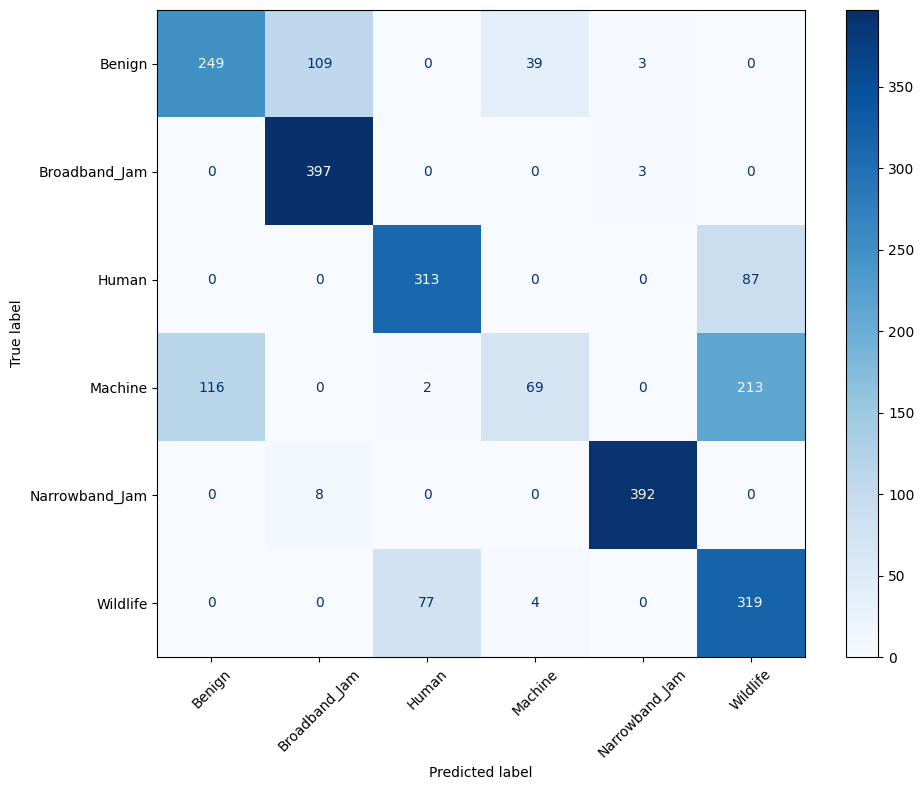

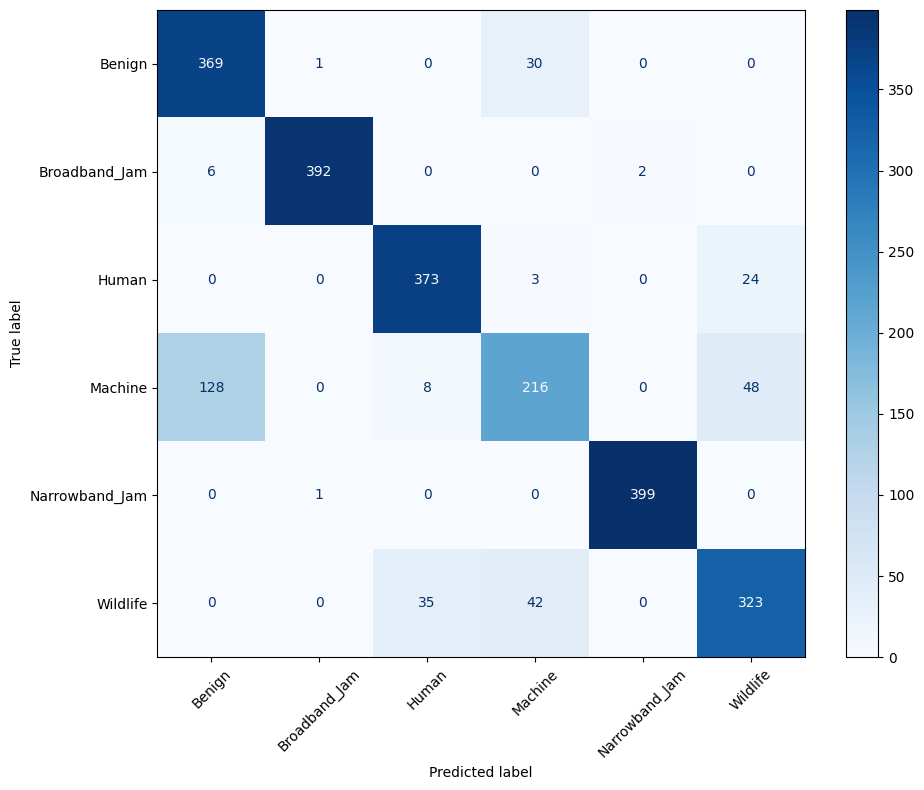

In [6]:
def evaluate_and_save(model, version, history):
    test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
    y_true = np.concatenate([np.argmax(labels.numpy(), axis=1) for _, labels in test_ds])
    y_pred = np.argmax(model.predict(test_ds), axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    metrics = {'test_loss': float(test_loss), 'test_accuracy': float(test_accuracy), 'macro_precision': float(precision), 'macro_recall': float(recall), 'macro_f1': float(f1), 'classification_report': classification_report(y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0), 'confusion_matrix': confusion_matrix(y_true, y_pred).tolist()}
    name = 'baseline_cnn_rf_intrusion_v1' if version == 'v1' else 'improved_cnn_rf_intrusion_v2'
    model.save(OUTPUT_DIR / f'{name}.keras')
    (OUTPUT_DIR / f'{name}_metadata.json').write_text(json.dumps({'model_version': version, 'class_names': class_names, 'input_shape': [128, 128, 3], 'evaluation': metrics, 'history': history.history, 'created_utc': datetime.now(timezone.utc).isoformat()}, indent=2))
    disp = ConfusionMatrixDisplay(confusion_matrix=np.array(metrics['confusion_matrix']), display_labels=class_names)
    fig, ax = plt.subplots(figsize=(10, 8)); disp.plot(ax=ax, cmap='Blues', values_format='d'); plt.xticks(rotation=45); plt.tight_layout(); fig.savefig(OUTPUT_DIR / f'{name}_confusion_matrix.png', dpi=160)
    return metrics

results = {'v1': evaluate_and_save(v1_model, 'v1', v1_history), 'v2': evaluate_and_save(v2_model, 'v2', v2_history)}

print("Overall test metrics")
for version, result in results.items():
    print(
        f"{version}: accuracy={result['test_accuracy']:.4f}, "
        f"precision={result['macro_precision']:.4f}, "
        f"recall={result['macro_recall']:.4f}, "
        f"F1={result['macro_f1']:.4f}, "
        f"loss={result['test_loss']:.4f}"
    )

print("\nPer-class precision / recall / F1")
for class_name in class_names:
    v1 = results["v1"]["classification_report"][class_name]
    v2 = results["v2"]["classification_report"][class_name]
    print(
        f"{class_name:16} | "
        f"v1 P/R/F1: {v1['precision']:.4f} / {v1['recall']:.4f} / {v1['f1-score']:.4f} | "
        f"v2 P/R/F1: {v2['precision']:.4f} / {v2['recall']:.4f} / {v2['f1-score']:.4f}"
    )

(OUTPUT_DIR / 'evaluation_results.json').write_text(json.dumps(results, indent=2))
print(json.dumps({version: {key: value for key, value in result.items() if key not in ('classification_report', 'confusion_matrix')} for version, result in results.items()}, indent=2))